<a href="https://colab.research.google.com/github/khalilMohaddere/Smart-Traffic-Monitoring-Vehicle-Counting/blob/main/Road%20Traffic%20Analytics%20Vehicle%20Detection%20Using%20SAHI%20and%20Faster%20R-CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -U git+https://github.com/obss/sahi
!pip install torch torchvision

  Cloning https://github.com/obss/sahi to /tmp/pip-req-build-jes3zvpx
  Running command git clone --filter=blob:none --quiet https://github.com/obss/sahi /tmp/pip-req-build-jes3zvpx
  Resolved https://github.com/obss/sahi to commit 10061afd5fa076e00f8eda55e2ee290f9d72f3c1
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for sahi: filename=sahi-0.14.0-py3-none-any.whl size=156625 sha256=7fb73078e82fb34fb170276ae6a017e9250c4b64842926c332a8b683aa7a8d81
  Stored in directory: /tmp/pip-ephem-wheel-cache-mqaq1bea/wheels/06/65/e6/bfee835e2c4d8d4406fef4a143de29e9a64fb673efe9b4eb55
Successfully built sahi
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [sahi]


In [ ]:
import os

os.getcwd()

'/content'

In [78]:

# import required functions, classes
from IPython.display import Image

from sahi import AutoDetectionModel
from sahi.predict import get_prediction, get_sliced_prediction, predict
from sahi.utils.cv import read_image
from sahi.utils.file import download_from_url

In [79]:
# set torchvision FasterRCNN model
import torchvision
from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights

model = torchvision.models.detection.fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)

Standard Inference with a Torchvision Model

In [80]:
detection_model = AutoDetectionModel.from_pretrained(
    model_type="torchvision",
    model=model,
    confidence_threshold=0.5,
    image_size=640,
    device="cpu",  # or "cuda:0"
    load_at_init=True,
)

In [81]:

result = get_prediction("traffic.png", detection_model)

In [82]:
result = get_prediction(read_image("traffic.png"), detection_model)

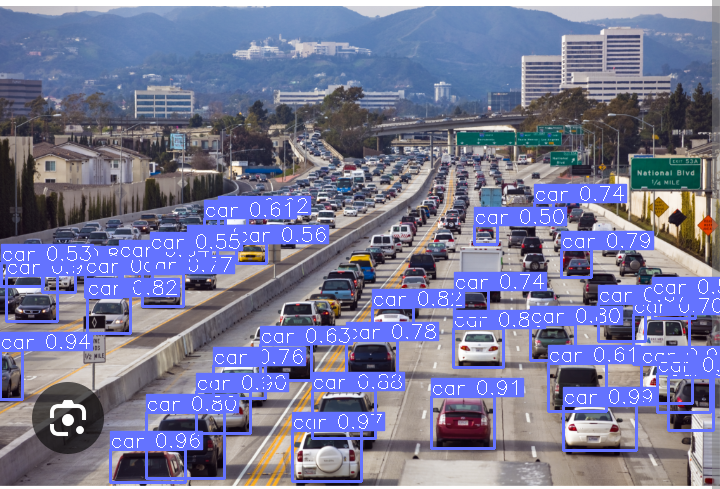

In [83]:
result.export_visuals(export_dir="demo_data/")
Image("demo_data/prediction_visual.png")

In [108]:
car_count = sum(1 for obj in object_prediction_list if obj.category.name == "car")
print("Number of cars:", car_count)
truck_count = sum(1 for obj in object_prediction_list if obj.category.name == "truck")
print("Number of truck:", truck_count)

Number of cars: 158
Number of truck: 22


2. Sliced Inference with a TorchVision Model

To perform sliced prediction we need to specify slice parameters. In this example we will perform prediction over slices of 320x320 with an overlap ratio of 0.2:

In [85]:
result = get_sliced_prediction(
    "traffic.png",
    detection_model,
    slice_height=320,
    slice_width=320,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
)

Performing prediction on 6 slices.


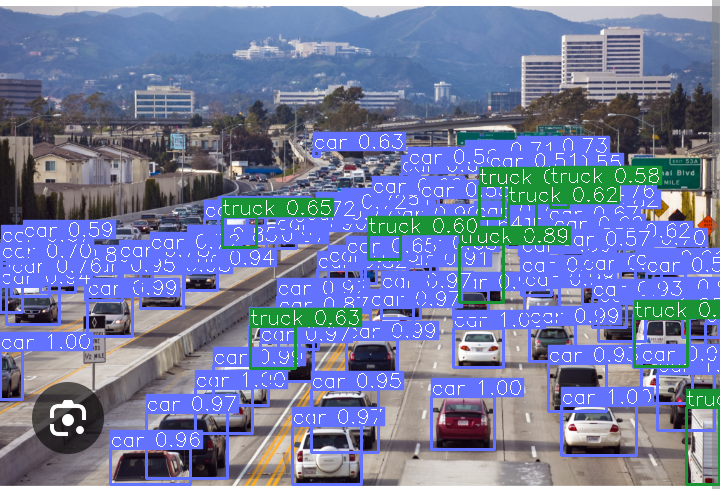

In [86]:
result.export_visuals(export_dir="demo_data/"
)
Image("demo_data/prediction_visual.png")

Prédiction result

In [87]:

object_prediction_list = result.object_prediction_list

In [88]:
object_prediction_list[20]

ObjectPrediction<
    bbox: BoundingBox: <(np.float64(236.64810180664062), np.float64(243.20089721679688), np.float64(266.0494384765625), np.float64(264.53709411621094)), w: 29.401336669921875, h: 21.336196899414062>,
    mask: None,
    score: PredictionScore: <value: 0.9692721962928772>,
    category: Category: <id: 3, name: car>>

In [89]:
result.to_coco_annotations()[:3]

[{'image_id': None,
  'bbox': [561.8538970947266,
   405.5419921875,
   74.66661071777344,
   50.33148193359375],
  'score': np.float32(0.9986966),
  'category_id': 3,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 3758},
 {'image_id': None,
  'bbox': [453.8413391113281,
   328.7522888183594,
   49.657684326171875,
   38.670501708984375],
  'score': np.float32(0.9974795),
  'category_id': 3,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 1920},
 {'image_id': None,
  'bbox': [0.04597756266593933,
   350.45562744140625,
   22.564869910478592,
   48.80438232421875],
  'score': np.float32(0.9957586),
  'category_id': 3,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 1101}]

In [90]:
result.to_coco_predictions(image_id=1)[:3]

[{'image_id': 1,
  'bbox': [561.8538970947266,
   405.5419921875,
   74.66661071777344,
   50.33148193359375],
  'score': np.float32(0.9986966),
  'category_id': 3,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 3758},
 {'image_id': 1,
  'bbox': [453.8413391113281,
   328.7522888183594,
   49.657684326171875,
   38.670501708984375],
  'score': np.float32(0.9974795),
  'category_id': 3,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 1920},
 {'image_id': 1,
  'bbox': [0.04597756266593933,
   350.45562744140625,
   22.564869910478592,
   48.80438232421875],
  'score': np.float32(0.9957586),
  'category_id': 3,
  'category_name': 'car',
  'segmentation': [],
  'iscrowd': 0,
  'area': 1101}]

In [91]:
!pip install -U imantics

In [92]:
result.to_imantics_annotations()[:3]

Batch Prediction

In [93]:
model = torchvision.models.detection.fasterrcnn_resnet50_fpn(pretrained=True)
detection_model = AutoDetectionModel.from_pretrained(
    model_type="torchvision",
    model=model,
    confidence_threshold=0.4,
    image_size=640,
    device="cpu",  # or "cuda:0"
    load_at_init=True,
)

slice_height = 256
slice_width = 256
overlap_height_ratio = 0.2
overlap_width_ratio = 0.2

source_image_dir = "demo_data/"

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=FasterRCNN_ResNet50_FPN_Weights.COCO_V1`. You can also use `weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [94]:
predict(
    detection_model=detection_model,
    source=source_image_dir,
    slice_height=slice_height,
    slice_width=slice_width,
    overlap_height_ratio=overlap_height_ratio,
    overlap_width_ratio=overlap_width_ratio,
)

There are 1 listed files in folder: demo_data/


Performing inference on images:   0%|          | 0/1 [00:00<?, ?it/s]

Performing prediction on 12 slices.


Performing inference on images: 100%|██████████| 1/1 [00:44<00:00, 44.74s/it]

Prediction time is: 44702.69 ms
Prediction results are successfully exported to runs/predict/exp3


Sliced Segmentation

In [98]:

maskrcnn_model = torchvision.models.detection.maskrcnn_resnet50_fpn(
    weights=torchvision.models.detection.MaskRCNN_ResNet50_FPN_Weights.DEFAULT
)
detection_model_seg = AutoDetectionModel.from_pretrained(
    model_type="torchvision",
    model=maskrcnn_model,
    confidence_threshold=0.5,
    mask_threshold=0.8,
    image_size=1333,
    device="cpu",  # or "cuda:0"
    load_at_init=True,
)
im = read_image("traffic.png")

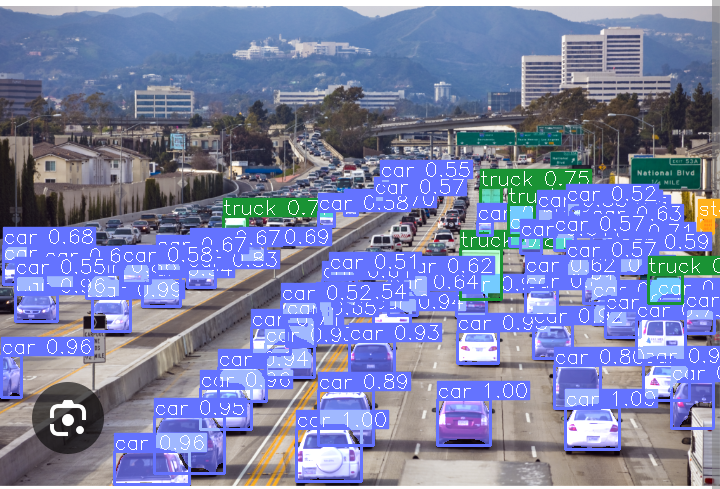

In [99]:

result = get_prediction(im, detection_model_seg)
result.export_visuals(export_dir="demo_data/")
Image("demo_data/prediction_visual.png")

In [100]:
result = get_sliced_prediction(
    im,
    detection_model_seg,
    slice_height=320,
    slice_width=320,
    overlap_height_ratio=0.2,
    overlap_width_ratio=0.2,
)

Performing prediction on 6 slices.


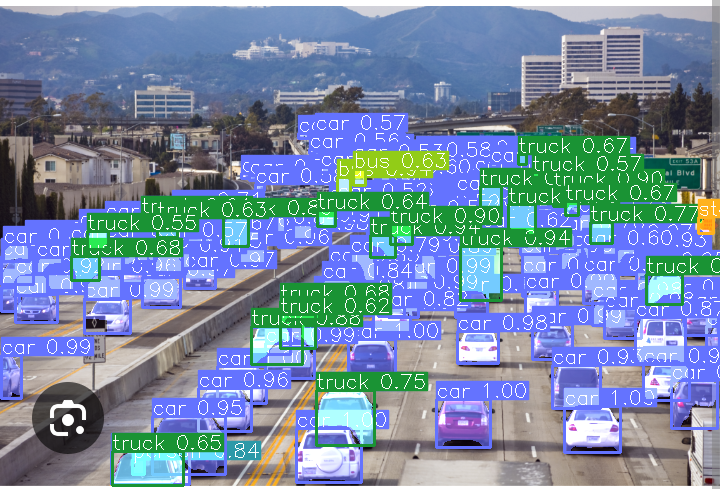

In [101]:
result.export_visuals(export_dir="demo_data/")
Image("demo_data/prediction_visual.png")

In [102]:
object_prediction_list = result.object_prediction_list
object_prediction_list[0]

ObjectPrediction<
    bbox: BoundingBox: <(132, 459, 144, 474), w: 12, h: 15>,
    mask: <sahi.annotation.Mask object at 0x7a9ae4926c10>,
    score: PredictionScore: <value: 0.8368497490882874>,
    category: Category: <id: 1, name: person>>

In [104]:
object_prediction_list[0].mask.segmentation

[[135,
  466,
  134,
  467,
  134,
  468,
  133,
  469,
  133,
  471,
  132,
  472,
  132,
  473,
  133,
  474,
  143,
  474,
  144,
  473,
  144,
  470,
  143,
  469,
  143,
  464,
  143,
  463,
  143,
  462,
  142,
  461,
  142,
  460,
  141,
  460,
  140,
  459,
  139,
  459,
  138,
  459,
  137,
  460,
  136,
  460,
  134,
  462,
  134,
  463,
  135,
  464]]

In [105]:
car_count = sum(1 for obj in object_prediction_list if obj.category.name == "car")
print("Number of cars:", car_count)

Number of cars: 158


In [106]:

truck_count = sum(1 for obj in object_prediction_list if obj.category.name == "truck")
print("Number of truck:", truck_count)

Number of truck: 22
